# Neuro-symbolic progression reasoning and patient reports

This iteration moves the project from "push the GNN score up" to the deliverable the mentor asked for:
**neuro-symbolic reasoning over the patient + PrimeKG graph, turned into per-patient reports** that say
whether and when a patient is predicted to progress, and *why*, in terms of explicit knowledge-graph
paths and explicit survival rules.

What is new in this run:

| Step | What it does | Where |
| --- | --- | --- |
| 1. Survival GNNs | GCN, GraphSAGE, R-GCN trained on the **full PFS follow-up** (1,083 patients, 145 progressions) with a Cox or C-index objective instead of the 36-month binary label | `stage_neural` |
| 2. Symbolic rules | **RuleKit LR-Rules** (log-rank rule induction) over 187 readable predicates: clinical facts, driver alterations, and **PrimeKG facts** ("an altered gene is in pathway P") | `src/neurosymbolic/rules.py` |
| 3. KG fact evidence | For every PrimeKG pathway / drug / disease node, a log-rank test of its carriers on the training folds | `src/neurosymbolic/kg_evidence.py` |
| 4. Fusion | A Cox model that stacks the GNN risk and the rule risk on the clinical block, compared with clinical baselines and a random survival forest | `stage_fusion` |
| 5. Timing | The month of progression, estimated from models fitted on training-fold progressors and checked against the recorded month | `src/neurosymbolic/timing.py` |
| 6. Paths | Every candidate KG path scored **0.6 × neural (GNNExplainer) + 0.4 × symbolic (fact evidence)**; top-K chosen by a prominence cutoff | `src/neurosymbolic/paths.py` |
| 7. Reports | Hospital-style PDF per patient, binned into progression-timeline groups A–D plus a no-progression group N | `scripts/build_patient_reports.py` |

Every number below is **out-of-fold**: each patient's prediction, rule set, and path scores come from models
trained on the four folds that exclude that patient. Follow-up time and event status are targets only; they
are never features.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'outputs' / 'neurosymbolic'
REPORTS = ROOT / 'outputs' / 'patient_reports'
from src.neurosymbolic import report_figures as F
from src.neurosymbolic.timing import GROUP_NAMES, window_label
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 140)
pred = pd.read_csv(OUT / 'fusion' / 'patient_predictions.csv')
timing = json.loads((OUT / 'fusion' / 'timing_evaluation.json').read_text())
print(f"{len(pred)} patients, {int(pred.event.sum())} recorded progressions, report model: {timing['report_model']}")

1083 patients, 145 recorded progressions, report model: neurosymbolic_cox


## 1. Cohort and report groups

Reports are binned by the **recorded** progression month, so a group never mixes true progressors with patients
who were never seen to progress. Only 12 of the 145 progressions happen within 6 months, so the first bin is
"within 12 months" rather than "within 3 or 6 months". Patients without a recorded progression form group N;
their absence of progression is censoring, not proof of remission, and the report says so (and flags short
follow-up).

In [2]:
order = ['A', 'B', 'C', 'D', 'N']
groups = pred.recorded_group.value_counts().reindex(order)
display(pd.DataFrame({'group': [f"{c} · {GROUP_NAMES[c]}" for c in order],
                      'recorded PFS': [window_label(c) if c != 'N' else 'censored' for c in order],
                      'patients': groups.values}))
fig, ax = plt.subplots(figsize=(8, 2.6))
months = pred.loc[pred.event == 1, 'time']
ax.hist(months, bins=np.arange(0, 200, 6), color='#2a78d6', rwidth=0.85)
for edge in (12, 24, 36):
    ax.axvline(edge, color='#52514e', linewidth=1)
ax.set_xlabel('Recorded progression (months)'); ax.set_ylabel('Patients')
ax.set_title('When the 145 recorded progressions happen (group edges at 12, 24, 36 months)', fontsize=9, loc='left')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#e4e3df'); ax.set_axisbelow(True)
plt.show()

,group,recorded PFS,patients
0,A · Early progression,≤ 12 months,32
1,B · Progression in year 2,12–24 months,30
2,C · Progression in year 3,24–36 months,27
3,D · Late progression,> 36 months,56
4,N · No progression recorded,censored,938


## 2. Neural part: survival GNNs on the fused patient + PrimeKG graph

The earlier benchmark optimised a 36-month binary label on 498 patients. Here the same fused graphs
(patient → sample → altered gene → PrimeKG pathway / drug / breast disease, 2 hops) are trained on the
full follow-up of all 1,083 patients, with the Breslow Cox likelihood or the differentiable C-index.
RGAT was dropped: one epoch took over five minutes on this machine.

In [3]:
neural = pd.read_csv(OUT / 'neural' / 'metrics.csv')
display(neural[['model', 'harrell_c', 'harrell_c_fold_mean', 'harrell_c_fold_std', 'uno_c_120', 'td_auc_12', 'td_auc_36', 'td_auc_60', 'minutes']].round(3))

,model,harrell_c,harrell_c_fold_mean,harrell_c_fold_std,uno_c_120,td_auc_12,td_auc_36,td_auc_60,minutes
0,gnn_graphsage_cox,0.595,0.603,0.062,0.556,0.585,0.637,0.589,6.164
1,gnn_gcn_cox,0.589,0.612,0.044,0.549,0.637,0.630,0.565,8.934
2,gnn_rgcn_cox,0.564,0.586,0.041,0.590,0.506,0.578,0.567,9.806
3,gnn_graphsage_cindex,0.599,0.622,0.067,0.573,0.598,0.619,0.618,2.951


The GNNs land at a fold-mean C-index of 0.59–0.62. That is the same saturation seen before: the graph adds
little beyond the clinical head every GNN carries. The best one (GraphSAGE, C-index objective) is kept as the
neural component, and its fold models produce the GNNExplainer edge importances used for the paths.

## 3. Symbolic part: survival rules over clinical, genomic, and PrimeKG predicates

Predicates are readable facts. Gene predicates keep driver mutations, driver CNAs, and amplicons (co-amplified
neighbours with Jaccard ≥ 0.8 are merged into one predicate named after a driver). PrimeKG predicates say that
an altered gene of the patient is annotated to a pathway or a breast-disease node. Binary predicates enter
RuleKit as "yes" or missing, so a rule can say "TP53 mutated" but never "RYR2 not mutated".

In [4]:
meta = json.loads((OUT / 'tables' / 'predicate_meta.json').read_text())
display(pd.Series(meta['kinds']).value_counts().rename('predicates').to_frame())
rules = pd.read_csv(OUT / 'symbolic' / 'rules.csv')
print(f"{len(rules)} rules over 5 folds; {int((rules.n_kg_conditions > 0).sum())} contain a PrimeKG condition")
fmt = {'hazard_ratio': '{:.2f}', 'median_months': '{:.0f}', 'pvalue': '{:.1e}'}
display(rules[rules.fold == 0][['rule_id', 'rule', 'coverage', 'events', 'hazard_ratio', 'median_months', 'pvalue']].style.format(fmt).hide(axis='index'))
print('Rules with a PrimeKG condition:')
display(rules[rules.n_kg_conditions > 0][['rule_id', 'rule', 'coverage', 'hazard_ratio', 'pvalue']].style.format(fmt).hide(axis='index'))
display(pd.read_csv(OUT / 'symbolic' / 'metrics.csv')[['model', 'harrell_c', 'harrell_c_fold_mean', 'harrell_c_fold_std', 'uno_c_120']].round(3))

,predicates
kg_pathway,116
genomic,58
clinical,10
kg_disease,4


39 rules over 5 folds; 4 contain a PrimeKG condition


rule_id,rule,coverage,events,hazard_ratio,median_months,pvalue
F1-R1,N stage = N0 AND Age ≥ 41.5 AND TMB (nonsynonymous) < 8.45,365,19,0.26,inf,4.0e-09
F1-R2,N stage = N0 AND Age ≥ 31.5,410,29,0.36,inf,4.5e-07
F1-R3,N stage = N3 AND 4.0 ≤ Aneuploidy score < 26.5,46,13,4.96,37,9.3e-08
F1-R4,AJCC stage = III AND Age ≥ 59.5 AND Aneuploidy score < 26.5,87,23,3.93,43,7.3e-10
F1-R5,AJCC stage = III AND altered gene linked to 'breast ductal adenocarcinoma' AND Aneuploidy score < 26.5,121,28,2.84,84,1.1e-06
F1-R6,AJCC stage = III AND Age ≥ 31.5,198,38,2.05,inf,2.0e-04
F1-R7,M stage = M0 AND Age ≥ 40.5 AND TMB (nonsynonymous) ≥ 0.02,609,61,0.36,168,1.8e-08
F1-R8,AJCC stage = II AND Age ≥ 39.5 AND TMB (nonsynonymous) < 141.95,452,39,0.47,168,7.9e-05


Rules with a PrimeKG condition:


rule_id,rule,coverage,hazard_ratio,pvalue
F1-R5,AJCC stage = III AND altered gene linked to 'breast ductal adenocarcinoma' AND Aneuploidy score < 26.5,121,2.84,1.1e-06
F2-R4,AJCC stage = III AND altered gene linked to 'breast ductal adenocarcinoma' AND Aneuploidy score ≥ 15.5,58,3.92,4.8e-08
F2-R5,AJCC stage = III AND altered gene linked to 'breast ductal adenocarcinoma' AND Age ≥ 35.0,123,2.94,1.4e-07
F3-R4,AJCC stage = III AND Aneuploidy score ≥ 6.5 AND altered gene in pathway 'CD28 dependent PI3K/Akt signaling',60,3.69,1.1e-07


,model,harrell_c,harrell_c_fold_mean,harrell_c_fold_std,uno_c_120
0,rulekit,0.592,0.619,0.048,0.623


Clinical facts (nodal stage, AJCC stage, age, aneuploidy) dominate the rules; four rules use a PrimeKG fact,
for example *AJCC stage III AND altered gene in pathway 'CD28 dependent PI3K/Akt signaling'*. A molecular-only
rule set (no clinical predicates) was also tried during development and did **not** generalise (held-out
C-index below 0.5), which is the symbolic face of the same finding as the GNN plateau.

### PrimeKG fact evidence

For the paths, every PrimeKG node gets a log-rank test of "patients with an altered gene annotated to this
node" versus the rest, computed separately on each training fold.

In [5]:
evidence = pd.read_csv(OUT / 'symbolic' / 'kg_evidence.csv')
fold0 = evidence[(evidence.fold == 0) & (evidence.carriers >= 30)].sort_values('z')
print(f"{evidence.fact.nunique()} PrimeKG facts with at least 15 carriers in a training fold")
display(pd.concat([fold0.head(5), fold0.tail(5)])[['fact', 'name', 'carriers', 'observed', 'expected', 'hazard_ratio', 'z']].round(2))

1053 PrimeKG facts with at least 15 carriers in a training fold


,fact,name,carriers,observed,expected,hazard_ratio,z
887,pathway:R-HSA-8856828,Clathrin-mediated endocytosis,151,12.0,21.74,0.50,-2.32
446,pathway:R-HSA-165159,MTOR signalling,38,1.0,5.61,0.17,-2.00
530,pathway:R-HSA-203615,eNOS activation,38,1.0,5.61,0.17,-2.00
142,drug:DB01863,"Inositol 1,3,4,5-Tetrakisphosphate",38,1.0,5.61,0.17,-2.00
426,pathway:R-HSA-1474151,"Tetrahydrobiopterin (BH4) synthesis, recycling, salvage and regulation",38,1.0,5.61,0.17,-2.00
428,pathway:R-HSA-1475029,Reversible hydration of carbon dioxide,91,18.0,11.15,1.73,2.16
83,drug:DB00819,Acetazolamide,91,18.0,11.15,1.73,2.16
580,pathway:R-HSA-3214815,HDACs deacetylate histones,97,20.0,11.81,1.84,2.52
579,pathway:R-HSA-3108214,SUMOylation of DNA damage response and repair proteins,231,42.0,28.99,1.70,2.80
294,drug:DB08846,Ellagic acid,186,36.0,23.75,1.75,2.82


## 4. Fusion and choosing the best model

All models are scored on the same five folds. The fused neuro-symbolic Cox model stacks the out-of-fold GNN risk
and RuleKit risk onto the 19-field clinical block (stacking caveat: a training patient's stacked inputs come
from fold models that saw other folds, the standard cross-validated stacking compromise).

,model,harrell_c,harrell_c_fold_mean,harrell_c_fold_std,uno_c_120,td_auc_12,td_auc_36,td_auc_60,integrated_brier_120
0,clinical_cox_19,0.669,0.675,0.035,0.616,0.691,0.710,0.621,0.134
1,clinical_cox_extended,0.666,0.667,0.042,0.657,0.687,0.677,0.633,0.135
2,neurosymbolic_cox,0.664,0.665,0.024,0.616,0.674,0.707,0.620,0.134
3,neurosymbolic_cox_extended,0.665,0.665,0.043,0.656,0.681,0.682,0.632,0.135
4,neural_symbolic_only,0.614,0.642,0.045,0.594,0.608,0.634,0.630,0.139
5,gnn_graphsage_cindex,0.599,0.622,0.067,0.573,0.598,0.619,0.618,NaN
6,rulekit,0.592,0.619,0.048,0.623,0.544,0.610,0.597,NaN
7,gnn_gcn_cox,0.589,0.612,0.044,0.549,0.637,0.630,0.565,NaN
8,gnn_graphsage_cox,0.595,0.603,0.062,0.556,0.585,0.637,0.589,NaN
9,gnn_rgcn_cox,0.564,0.586,0.041,0.590,0.506,0.578,0.567,NaN


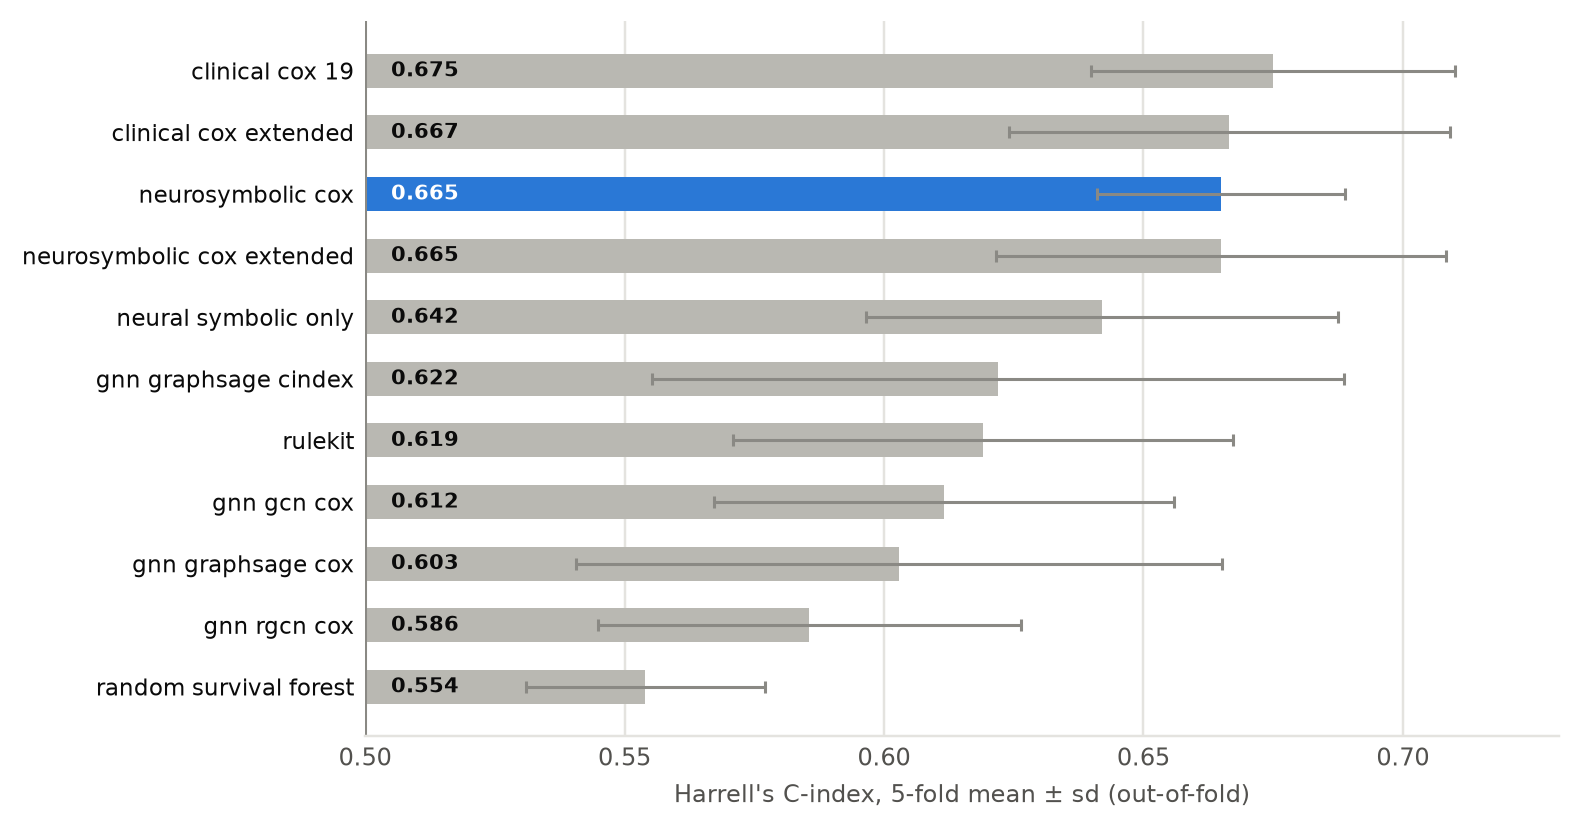

Best fold-mean C: clinical_cox_19 0.675; one standard error = 0.016; bar = 0.659
Within one SE of the best: clinical_cox_19, clinical_cox_extended, neurosymbolic_cox, neurosymbolic_cox_extended
Report model: neurosymbolic_cox - within one standard error of the best (clinical_cox_19)


,coef,exp(coef),p
covariate,,,
gnn_risk,-0.027,0.973,0.584
rule_risk,-0.001,0.999,0.779


In [6]:
metrics = pd.read_csv(OUT / 'fusion' / 'metrics.csv')
display(metrics[['model', 'harrell_c', 'harrell_c_fold_mean', 'harrell_c_fold_std', 'uno_c_120', 'td_auc_12', 'td_auc_36', 'td_auc_60', 'integrated_brier_120']].round(3))
display(Image(F.model_comparison_figure(metrics.model.str.replace('_', ' ').tolist(), metrics.harrell_c_fold_mean.tolist(), metrics.harrell_c_fold_std.tolist(), timing['report_model'].replace('_', ' '))))
sel = timing['selection']
print(f"Best fold-mean C: {sel['best_model']} {sel['best_c']:.3f}; one standard error = {sel['standard_error']:.3f}; bar = {sel['bar']:.3f}")
print('Within one SE of the best:', ', '.join(sel['eligible']))
print('Report model:', timing['report_model'], '-', sel['reason'])
coef = pd.read_csv(OUT / 'fusion' / 'neurosymbolic_coefficients.csv')
display(coef[coef.covariate.isin(['gnn_risk', 'rule_risk'])].groupby('covariate')[['coef', 'exp(coef)', 'p']].mean().round(3))

**How the model was chosen.** The top four models differ by less than 0.01 in fold-mean C-index while the fold
standard deviation is about 0.04. They are statistically tied. Following the one-standard-error rule, the report
model is the most explainable model within one standard error of the best: the **neuro-symbolic Cox model**
(clinical block + GNN risk + rule risk). It matches the best clinical model's discrimination and is the only
candidate whose prediction decomposes into knowledge-graph paths and rules, which is what the reports show.

The honest headline: **discrimination is saturated at a C-index of about 0.67 whatever the model family**:
GNN, rules, forests, and Cox all reach the same ceiling. With 145 progressions, the clinical signal (nodal stage,
stage, age, subtype) carries most of it. The coefficient table above makes this concrete: once the clinical block
is in the model, the GNN risk and the rule risk get hazard ratios of about 0.95–1.05 per standard deviation with
p > 0.5 in every fold, so the fused risk is essentially the clinical risk. Without the clinical block the neural
and symbolic risks together reach about 0.64, better than either alone, but all of that information is already
in the clinical fields. The neuro-symbolic layer contributes **explanation, not extra accuracy**. If a purely
clinical risk is preferred in the reports, `--report-model clinical_cox_19` swaps it in.

## 5. When will progression happen? Predicting the month

A Cox curve's plain median is undefined for most patients (most never progress). The report therefore estimates
the **time to progression given that progression happens**. Candidates, all scored on held-out progressors:
conditional medians of the fused model's curve (`F(t)/F(τ) = ½` for three horizons τ), log-normal and
log-logistic AFT models fitted on training-fold progressors, and a constant baseline (the median of
training-fold progressors).

,patients,mae_months,median_abs_error_months,within_12_months,window_accuracy,interval_coverage
conditional_median_tau60,145.0,23.290,18.225,0.331,0.172,0.366
conditional_median_tau120,145.0,27.971,24.578,0.234,0.386,0.407
conditional_median_tau180,145.0,59.444,63.145,0.069,0.393,0.324
training_progressor_median,145.0,22.885,15.978,0.372,0.186,0.490
lognormal_aft_on_progressors,145.0,21.081,12.571,0.497,0.338,0.559
loglogistic_aft_on_progressors,145.0,20.425,11.579,0.510,0.345,0.593


Chosen estimator: loglogistic_aft_on_progressors


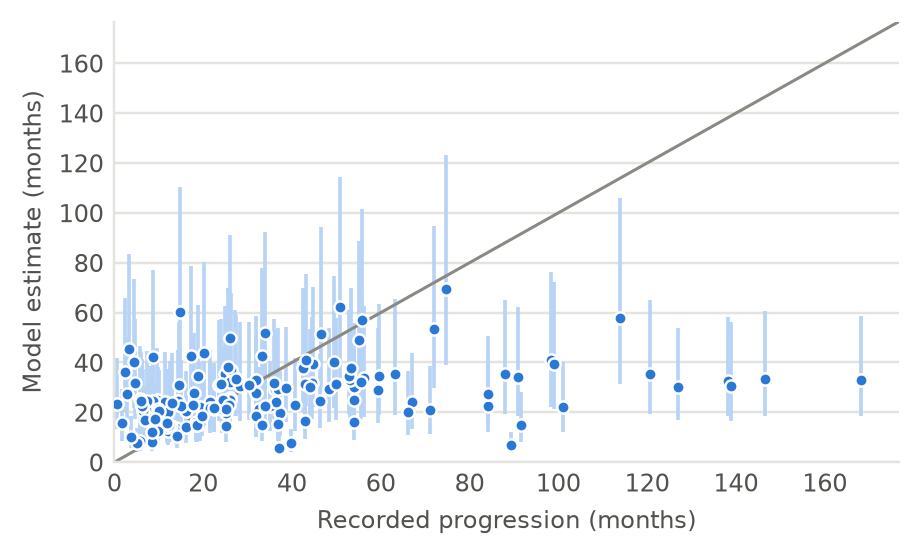

Recorded window (rows) vs model window (columns), held-out progressors:


predicted_window,A,B,C,D
recorded_group,,,,
A,5,15,8,4
B,1,19,7,3
C,0,10,12,5
D,3,10,29,14


In [7]:
rows = pd.DataFrame(timing['estimators']).T
display(rows[['patients', 'mae_months', 'median_abs_error_months', 'within_12_months', 'window_accuracy', 'interval_coverage']].round(3))
print('Chosen estimator:', timing['chosen_estimator'])
prog = pred[pred.event == 1]
display(Image(F.predicted_vs_recorded_figure(prog.time.values, prog.predicted_month.values, prog.predicted_low.values, prog.predicted_high.values, width=4.6)))
print('Recorded window (rows) vs model window (columns), held-out progressors:')
display(pd.crosstab(prog.recorded_group, prog.predicted_window))

Compared with the constant baseline, the chosen estimator halves the gap to the correct window (window accuracy
rises from about 0.19 to 0.34; chance with four windows is about 0.25) and puts about half of the estimates within
12 months of the recorded progression. Its median absolute error is about 12 months, but the mean is about 20,
because late progressions (5–15 years) are hard to place. Several estimator variants were compared on the same
held-out progressors, so the chosen row is mildly optimistic. The report always prints the **recorded** month
next to the estimate and marks whether the estimate fell in the recorded window, so a reader never takes the
estimate for the record.

## 6. Neuro-symbolic paths and the top-K rule

Each candidate path is a real walk over stored edges: patient → sample → altered gene → (protein partner) →
pathway / drug / breast disease. It gets

* **neural** = percentile of its mean GNNExplainer edge importance (fold model that held the patient out),
* **symbolic** = |log-rank z| of the PrimeKG fact it ends in, from that patient's training folds, capped at 3 and scaled to [0, 1],
* **NS score** = 0.6 × neural + 0.4 × symbolic.

A path is *prominent* when its NS score is in the cohort's top 20%. A report shows `min(5, prominent)` paths
(at most two through the same gene, each gene route and end node once); when fewer than three are prominent it
tops up with the best remaining paths and says so. Most patients land on K = 3 for that reason; 50 patients have
no path at all because none of their altered genes has a PrimeKG pathway, drug, or breast-disease link.

In [8]:
from src.neurosymbolic.report_pdf import load_context
ctx = load_context(OUT)
scored = ctx.scored_paths
print(f"{len(scored)} candidate paths over {scored.patient_id.nunique()} patients; prominence cutoff NS ≥ {ctx.cutoff:.3f}")
shown = pd.Series({pid: len(ctx.paths_for(pid)) for pid in ctx.patient_ids})
prominent = pd.Series({pid: int(ctx.paths_for(pid)['prominent'].sum()) if len(ctx.paths_for(pid)) else 0 for pid in ctx.patient_ids})
display(pd.DataFrame({'paths shown (K)': shown.value_counts().sort_index(), 'patients with this many prominent paths': prominent.value_counts().sort_index()}).fillna(0).astype(int))
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.hist(scored.ns_score, bins=60, color='#1c5cab', rwidth=0.9)
ax.axvline(ctx.cutoff, color='#e34948', linewidth=1.5)
ax.text(ctx.cutoff, ax.get_ylim()[1] * 0.9, '  prominence cutoff', color='#0b0b0b', fontsize=8)
ax.set_xlabel('Neuro-symbolic path score'); ax.set_ylabel('Candidate paths')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#e4e3df'); ax.set_axisbelow(True)
plt.show()

59598 candidate paths over 1033 patients; prominence cutoff NS ≥ 0.567


,paths shown (K),patients with this many prominent paths
0,50,397
1,21,182
2,81,171
3,726,128
4,78,78
5,127,127


Example patients: {'A': 'TCGA-UU-A93S', 'B': 'TCGA-C8-A12Q', 'C': 'TCGA-A2-A3XY', 'D': 'TCGA-B6-A0X7', 'N': 'TCGA-S3-AA14'}


**Top paths for TCGA-UU-A93S** (group A, recorded progression at 3.8 months)

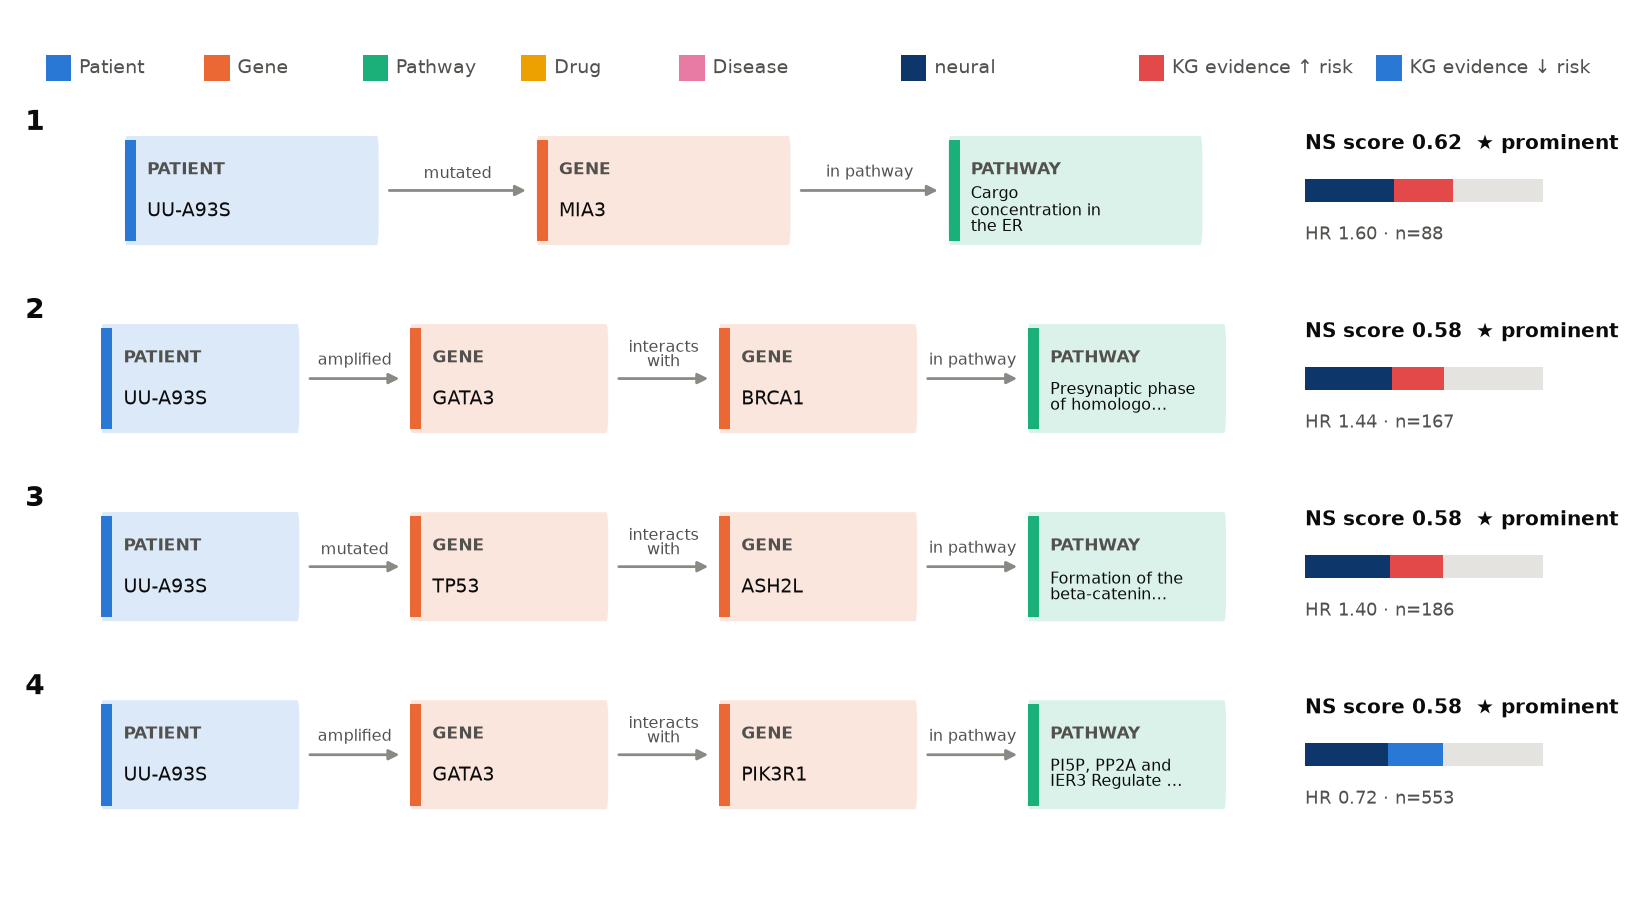

,rank,altered_gene,terminal_name,neural,fact_hazard_ratio,fact_carriers,symbolic,ns_score,prominent
0,1,MIA3,Cargo concentration in the ER,0.622,1.603,88.0,0.622,0.622,True
1,2,GATA3,Presynaptic phase of homologous DNA pairing and strand exchange,0.609,1.443,167.0,0.544,0.583,True
2,3,TP53,Formation of the beta-catenin:TCF transactivating complex,0.599,1.402,186.0,0.551,0.580,True
3,4,GATA3,"PI5P, PP2A and IER3 Regulate PI3K/AKT Signaling",0.580,0.724,553.0,0.578,0.579,True


In [9]:
examples = {}
for code in ['A', 'B', 'C', 'D', 'N']:
    members = pred[pred.recorded_group == code].sort_values('risk_percentile', ascending=(code == 'N'))
    for pid in members.patient_id:
        paths = ctx.paths_for(pid)
        if len(paths) >= 3 and paths['prominent'].sum() >= 2:
            examples[code] = pid
            break
    examples.setdefault(code, members.patient_id.iloc[0])
print('Example patients:', examples)
pid = examples['A']
paths = ctx.paths_for(pid)
display(Markdown(f'**Top paths for {pid}** (group A, recorded progression at {pred.set_index("patient_id").loc[pid, "time"]:.1f} months)'))
display(Image(F.path_figure(paths.to_dict('records'))))
display(paths[['rank', 'altered_gene', 'terminal_name', 'neural', 'fact_hazard_ratio', 'fact_carriers', 'symbolic', 'ns_score', 'prominent']].round(3))

## 7. The patient reports

`scripts/build_patient_reports.py` writes one PDF per patient into its group folder, a summary per group
(group statistics, most frequent path end-points and rules, driver alterations, and an index of every patient),
a combined PDF for each progression group, and a cohort overview. Each patient report has:

1. **Patient and tumour record**: demographics, PAM50 subtype, AJCC stage and TNM, histology, therapy history, aneuploidy, TMB, MSI.
2. **Progression assessment**: risk percentile and tier, probability of progression by 12/24/36/60 months, the model-estimated progression month and window, the recorded outcome with a ✓/✗ against the estimate, the patient's survival curve against the cohort, and a plain-language summary.
3. **Neuro-symbolic reasoning**: the top-K knowledge-graph paths drawn as chains with their neural/symbolic score split, a path table with the PrimeKG fact evidence, and the RuleKit rules that fire for the patient with the strongest rule's Kaplan–Meier curve.
4. **Molecular profile and KG context**: altered genes (drivers first) with protein change and PrimeKG links, GNN gene importance, PrimeKG drug links (research context only), and the five most similar patients with their recorded outcomes.

Group N reports carry the same reasoning; their outcome tile states the follow-up length and flags short
follow-up, because no progression is not the same as no risk.

In [10]:
rows = []
for folder in sorted(p for p in REPORTS.iterdir() if p.is_dir()):
    pdfs = [p for p in folder.glob('*.pdf') if not p.name.startswith(('00_', 'group_'))]
    rows.append({'folder': folder.name, 'patient reports': len(pdfs), 'group files': ', '.join(sorted(p.name for p in folder.glob('*.pdf') if p.name.startswith(('00_', 'group_'))))})
display(pd.DataFrame(rows))

,folder,patient reports,group files
0,A_progression_within_12m,32,"00_group_A_summary.pdf, group_A_all_reports.pdf"
1,B_progression_12-24m,30,"00_group_B_summary.pdf, group_B_all_reports.pdf"
2,C_progression_24-36m,27,"00_group_C_summary.pdf, group_C_all_reports.pdf"
3,D_progression_after_36m,56,"00_group_D_summary.pdf, group_D_all_reports.pdf"
4,N_no_progression,938,00_group_N_summary.pdf


### Full report: TCGA-UU-A93S (group A)

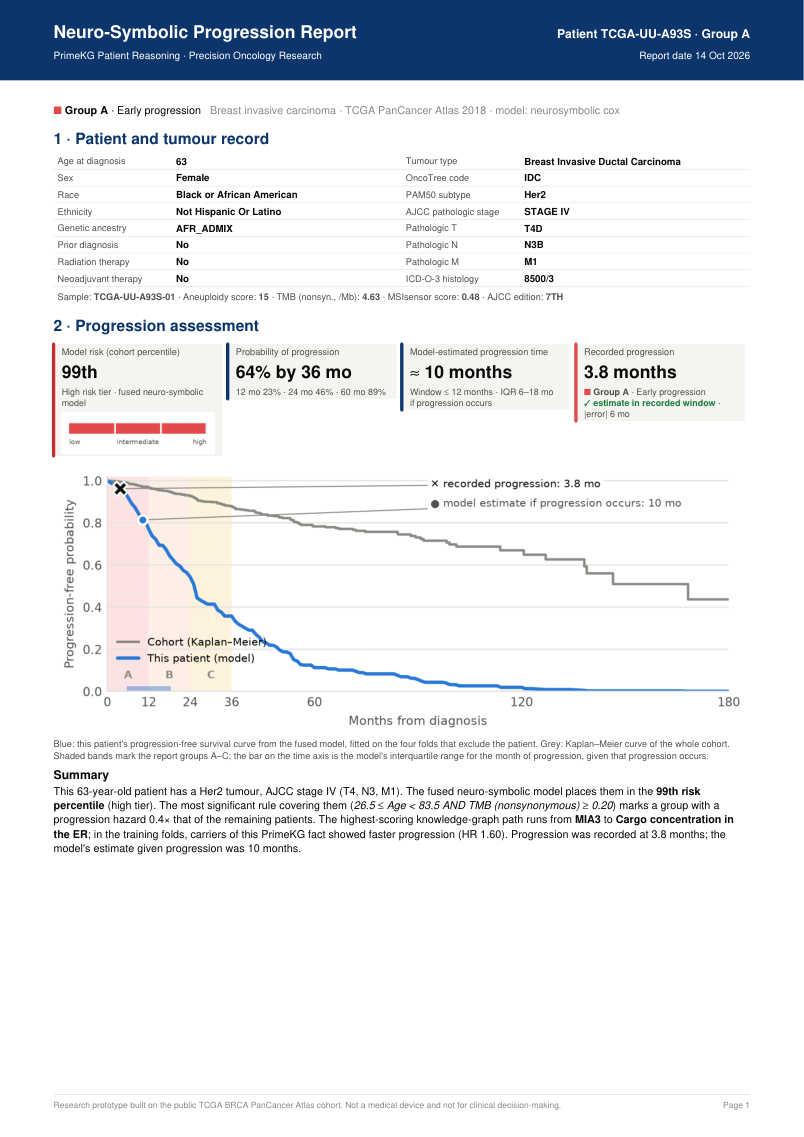

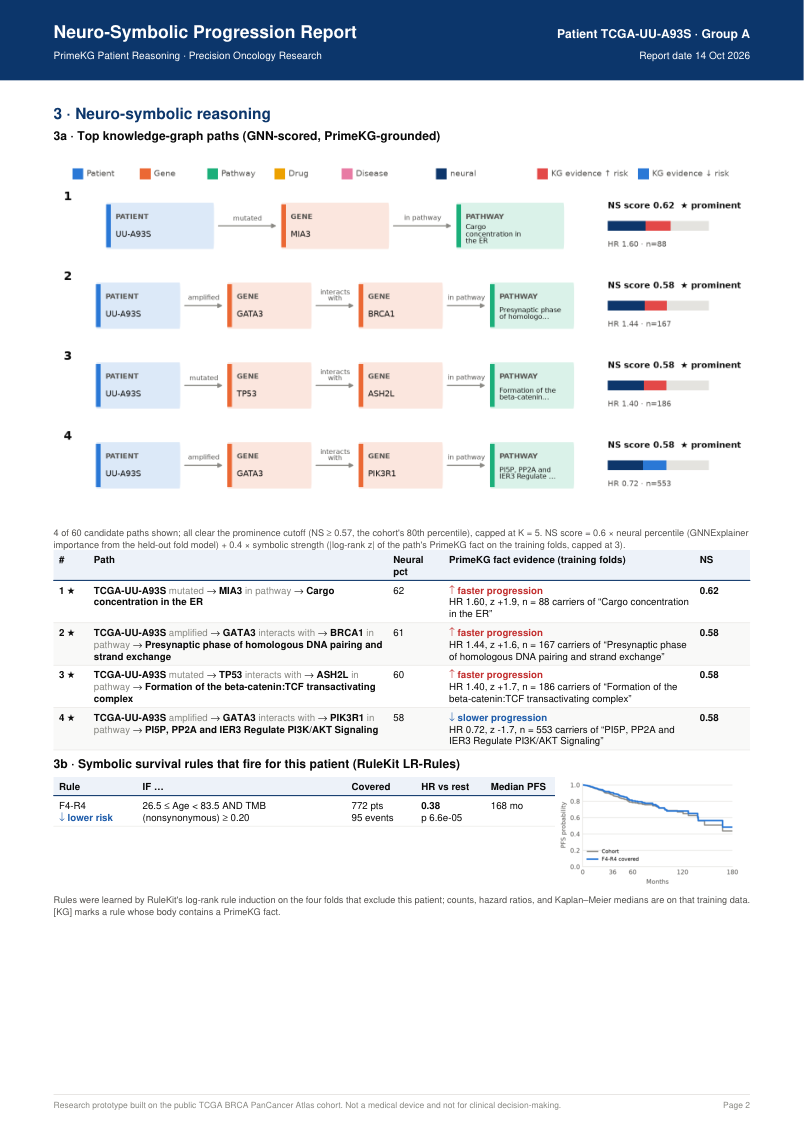

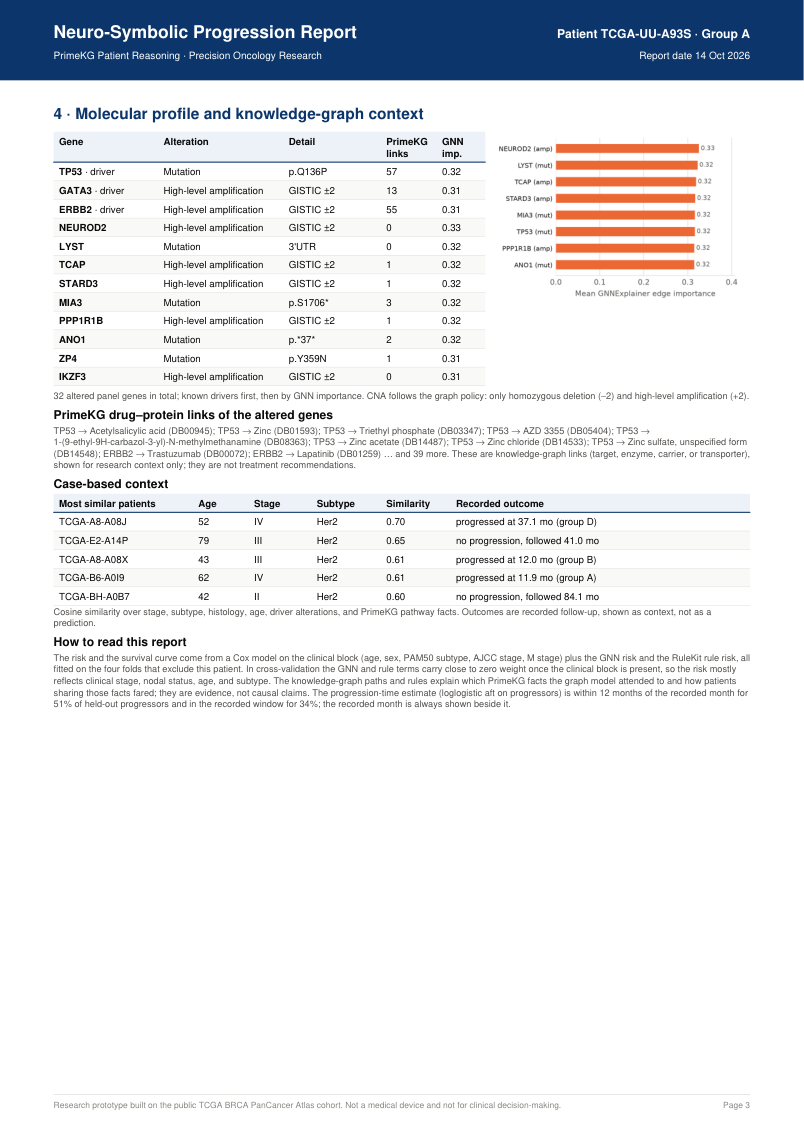

In [11]:
import pymupdf  # renders a PDF page to an image for the notebook

def show_pdf(path, pages=(0,), zoom=1.35):
    doc = pymupdf.open(path)
    for page in pages:
        if page < len(doc):
            display(Image(doc[page].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom)).tobytes('png')))

folders = {'A': 'A_progression_within_12m', 'B': 'B_progression_12-24m', 'C': 'C_progression_24-36m', 'D': 'D_progression_after_36m', 'N': 'N_no_progression'}
pid = examples['A']
display(Markdown(f'### Full report: {pid} (group A)'))
show_pdf(REPORTS / folders['A'] / f'{pid}.pdf', pages=(0, 1, 2))

### Group B example: TCGA-C8-A12Q, page 1

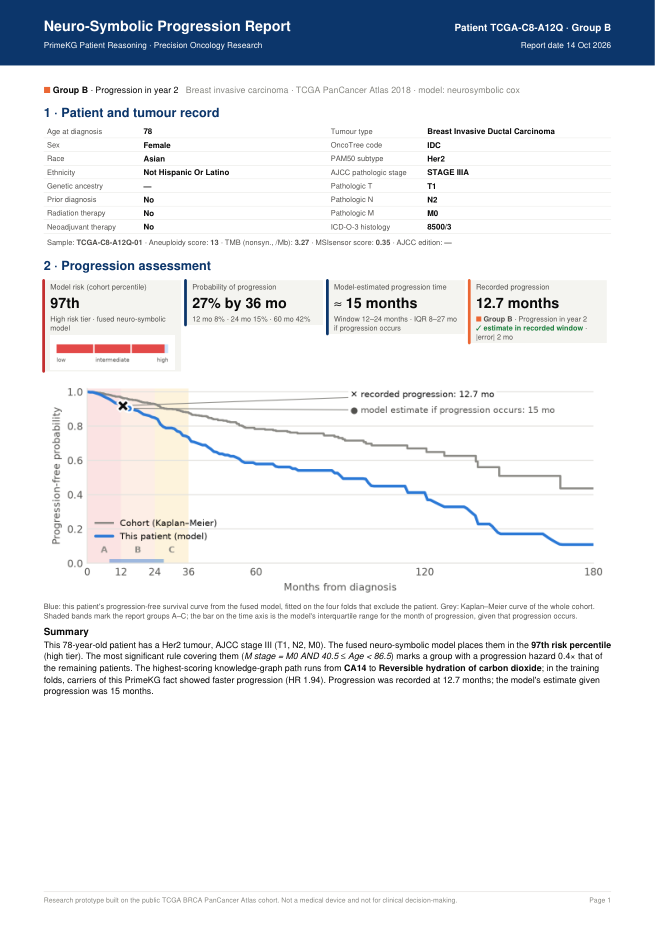

### Group C example: TCGA-A2-A3XY, page 1

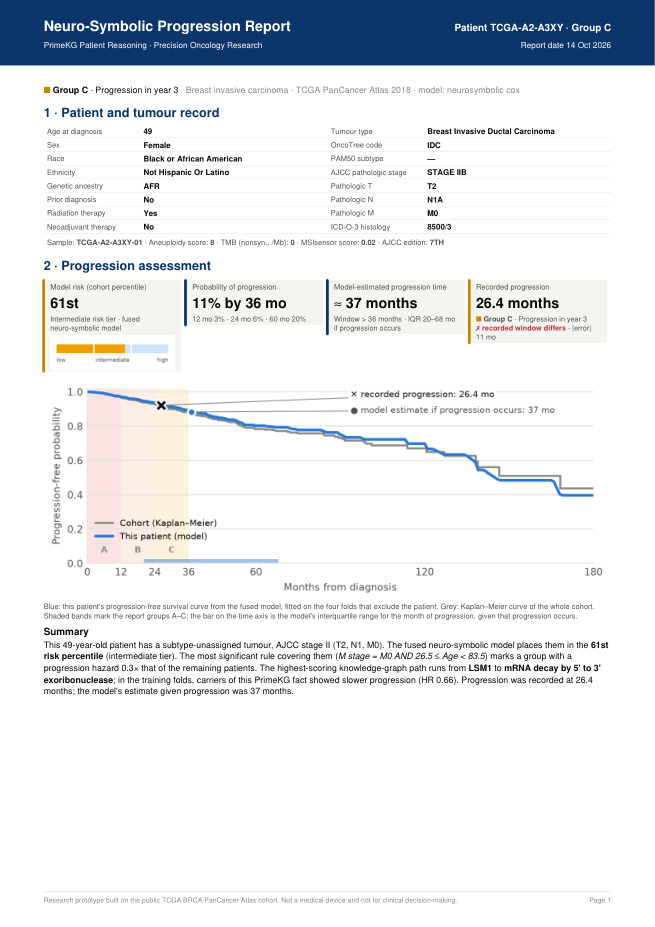

### Group D example: TCGA-B6-A0X7, page 1

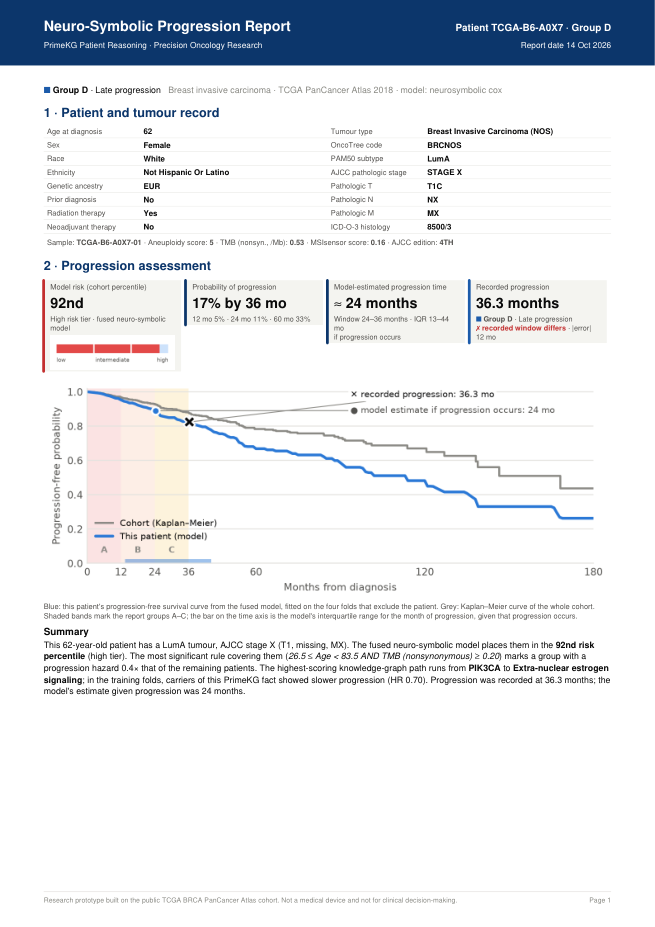

### Group N example: TCGA-S3-AA14, page 1

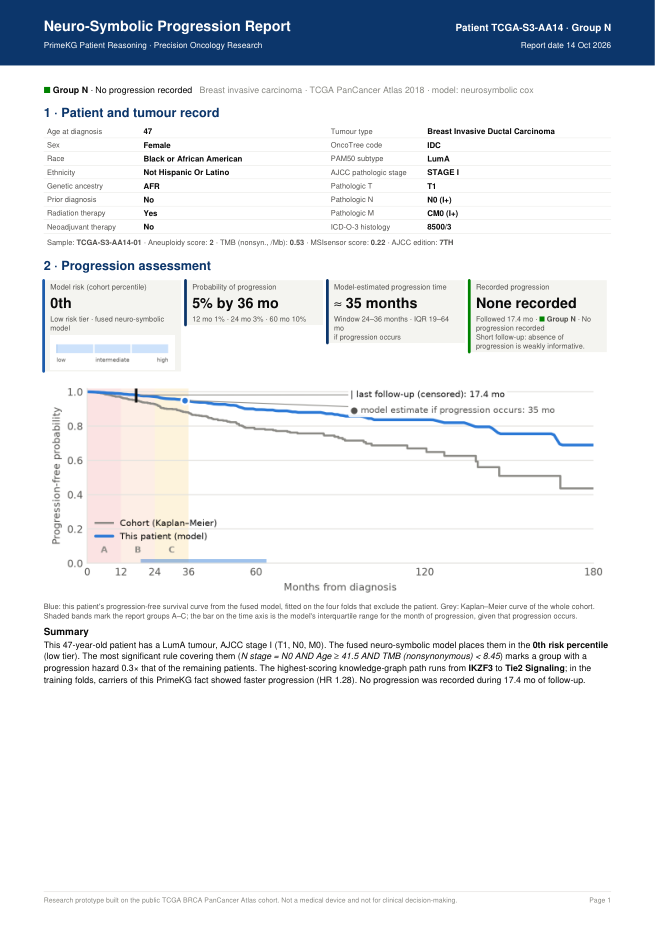

In [12]:
for code in ['B', 'C', 'D', 'N']:
    pid = examples[code]
    display(Markdown(f'### Group {code} example: {pid}, page 1'))
    show_pdf(REPORTS / folders[code] / f'{pid}.pdf', pages=(0,), zoom=1.1)

### Group A summary page and cohort overview

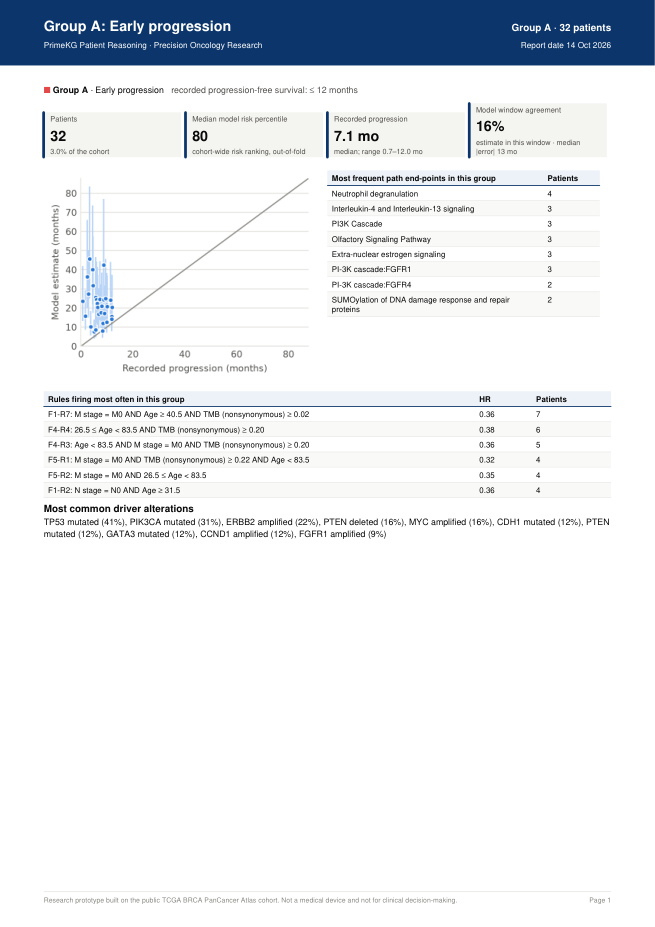

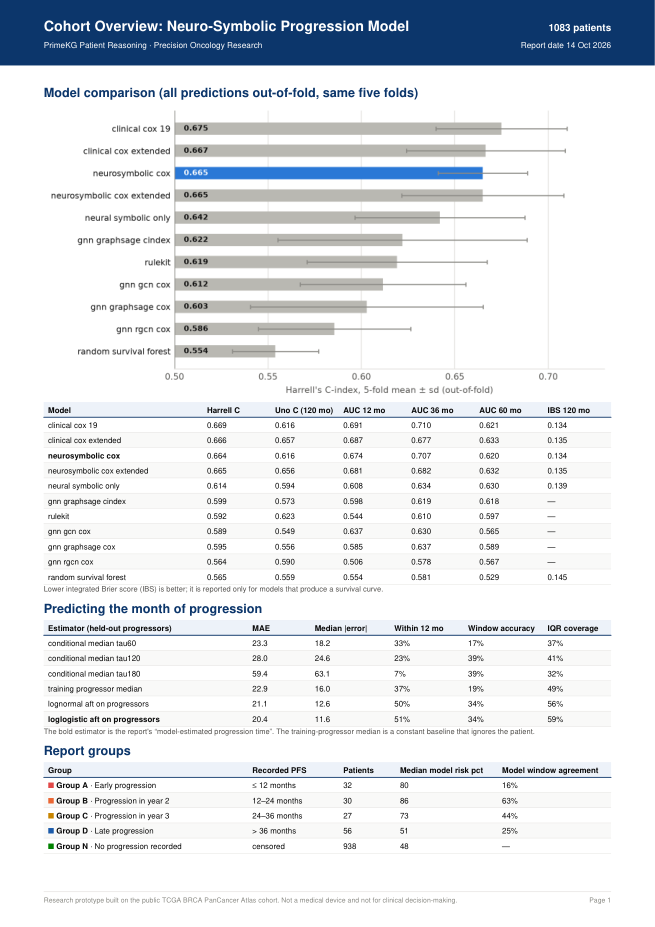

In [13]:
display(Markdown('### Group A summary page and cohort overview'))
show_pdf(REPORTS / folders['A'] / '00_group_A_summary.pdf', pages=(0,), zoom=1.1)
show_pdf(REPORTS / '00_cohort_overview.pdf', pages=(0,), zoom=1.1)

## 8. Limitations to keep in mind

* **Discrimination is saturated** at a C-index of about 0.67. The neuro-symbolic model is chosen because it is
  tied with the best and explainable, not because it is more accurate.
* **Timing is coarse.** The month estimate is right to within a year for about half of the progressors; late
  progressions are hard to place. The recorded month is always printed beside it.
* **Paths explain the GNN, which is the weaker component.** A path is evidence of what the graph model attended
  to, paired with cohort-level evidence for the PrimeKG fact; it is not a causal claim.
* **PrimeKG drug links are not recommendations.** They include enzymes, carriers, and transporters as well as targets.
* **One cohort, one seed, five folds.** No external validation of the reports; the stacked fusion uses the
  standard cross-validated stacking compromise.

Reproduce everything with:

```bash
python scripts/run_neurosymbolic_pipeline.py          # neural, symbolic, fusion, explain (~45 min on a laptop CPU)
python scripts/build_patient_reports.py --workers 4   # ~1,083 PDFs + group summaries
python scripts/build_neurosymbolic_notebook.py        # this notebook
```